# Player Data Visualization

## Objective

Create interactive visualizations to explore football player statistics,
compare player profiles, understand attribute distributions and interpret
machine learning results.

## Visualization Components

1. Player Attribute Radar Charts
2. Attribute Distribution Analysis
3. Position-wise Comparisons
4. Player Percentile Analysis
5. Player Similarity Visualization
6. Playing-Style Cluster Visualization
7. Top Player Rankings

## Libraries

- Matplotlib
- Seaborn
- Plotly
- Pandas
- NumPy

In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from pathlib import Path

PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(DATA_DIR / "players_engineered.csv")
df_clustered = pd.read_csv(DATA_DIR / "players_clustered.csv")
cluster_summary = pd.read_csv(DATA_DIR / "cluster_summary.csv")

print("Engineered dataset:", df.shape)
print("Clustered dataset:", df_clustered.shape)
print("Cluster summary:", cluster_summary.shape)

print("\nAvailable positions:")
print(df["Pos"].value_counts())

Engineered dataset: (1692, 109)
Clustered dataset: (1692, 112)
Cluster summary: (12, 10)

Available positions:
Pos
DF    702
MF    564
FW    426
Name: count, dtype: int64


In [34]:
ATTRIBUTE_LABELS = [
    "Finishing",
    "Creativity",
    "Passing",
    "Progression",
    "Defending",
    "Ball Security",
    "Aerial"
]

ATTRIBUTE_COLUMNS = [
    "Finishing_Score",
    "Creativity_Score",
    "Passing_Score",
    "Progression_Score",
    "Defending_Score",
    "BallSecurity_Score",
    "Aerial_Score"
]


def plot_player_radar(player_name):

    player = df[df["Player"] == player_name]

    if player.empty:
        raise ValueError(f"Player '{player_name}' not found.")

    if len(player) > 1:
        raise ValueError(
            "Multiple players share this name. "
            "Use a unique player identifier."
        )

    player = player.iloc[0]

    values = player[ATTRIBUTE_COLUMNS].tolist()

    # Close the radar chart
    values += values[:1]
    categories = ATTRIBUTE_LABELS + ATTRIBUTE_LABELS[:1]

    fig = go.Figure()

    fig.add_trace(go.Scatterpolar(
        r=values,
        theta=categories,
        fill="toself",
        name=player_name
    ))

    fig.update_layout(
        title=f"{player_name} - Attribute Profile",
        polar=dict(
            radialaxis=dict(
                visible=True,
                range=[0, 100]
            )
        ),
        showlegend=False,
        template="plotly_white"
    )

    fig.show()

In [35]:
plot_player_radar("Erling Haaland")

In [36]:
def compare_players_radar(player1_name, player2_name):

    player1 = df[df["Player"] == player1_name]
    player2 = df[df["Player"] == player2_name]

    if len(player1) != 1 or len(player2) != 1:
        raise ValueError(
            "Each player name must uniquely identify one player."
        )

    player1 = player1.iloc[0]
    player2 = player2.iloc[0]

    # Ensure both players belong to the same position group
    if player1["Pos"] != player2["Pos"]:
        raise ValueError(
            "Compare players from the same position group."
        )

    values1 = player1[ATTRIBUTE_COLUMNS].tolist()
    values2 = player2[ATTRIBUTE_COLUMNS].tolist()

    categories = ATTRIBUTE_LABELS + ATTRIBUTE_LABELS[:1]

    values1 += values1[:1]
    values2 += values2[:1]

    fig = go.Figure()

    fig.add_trace(go.Scatterpolar(
        r=values1,
        theta=categories,
        fill="toself",
        name=player1_name
    ))

    fig.add_trace(go.Scatterpolar(
        r=values2,
        theta=categories,
        fill="toself",
        name=player2_name
    ))

    fig.update_layout(
        title=f"{player1_name} vs {player2_name}",
        polar=dict(
            radialaxis=dict(
                visible=True,
                range=[0, 100]
            )
        ),
        template="plotly_white"
    )

    fig.show()

In [37]:
compare_players_radar(
    "Erling Haaland",
    "Ollie Watkins"
)

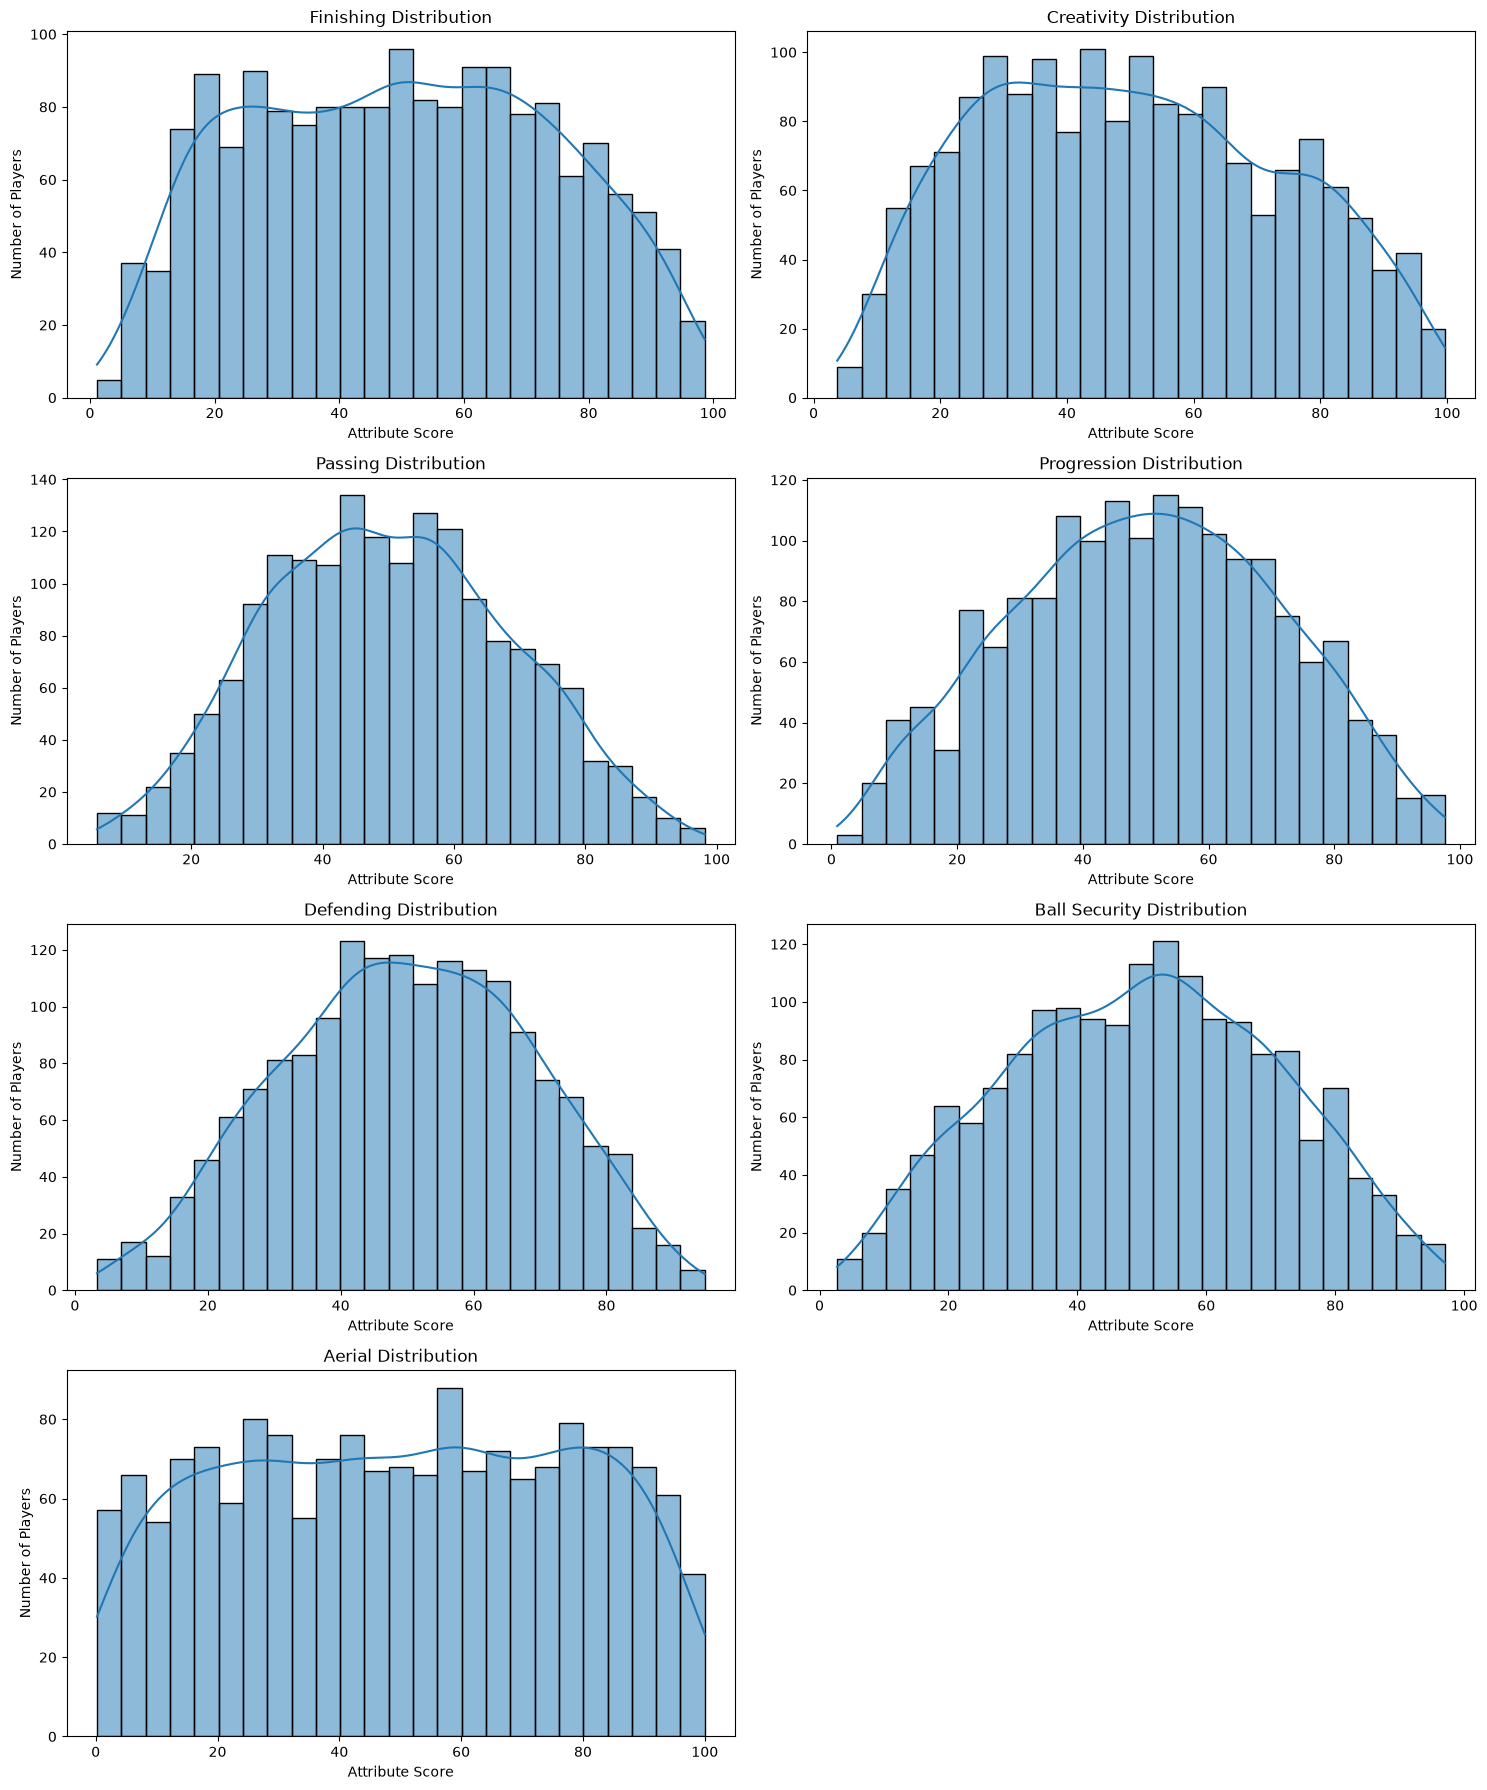

In [38]:
fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for i, column in enumerate(ATTRIBUTE_COLUMNS):

    row = i // 2
    col = i % 2

    sns.histplot(
        data=df,
        x=column,
        bins=25,
        kde=True,
        ax=axes[row, col]
    )

    axes[row, col].set_title(
        f"{ATTRIBUTE_LABELS[i]} Distribution"
    )

    axes[row, col].set_xlabel("Attribute Score")
    axes[row, col].set_ylabel("Number of Players")

# Remove unused subplot
fig.delaxes(axes[3, 1])

plt.tight_layout()
plt.show()

In [39]:
display(
    df[ATTRIBUTE_COLUMNS]
    .describe()
    .round(2)
)

,Finishing_Score,Creativity_Score,Passing_Score,Progression_Score,Defending_Score,BallSecurity_Score,Aerial_Score
count,1692.00,1692.00,1692.00,1692.00,1692.00,1692.00,1692.00
mean,50.05,50.09,50.09,50.09,50.09,50.09,50.09
std,23.91,23.33,18.33,20.96,18.78,20.87,27.82
min,1.13,3.72,5.66,0.92,3.33,2.74,0.21
25%,29.34,30.73,36.50,34.74,36.63,34.24,26.56
50%,50.05,48.79,49.28,50.39,50.25,50.59,50.16
75%,68.92,67.92,63.20,65.88,64.07,66.01,74.17
max,98.64,99.69,98.20,97.62,94.80,97.03,100.00


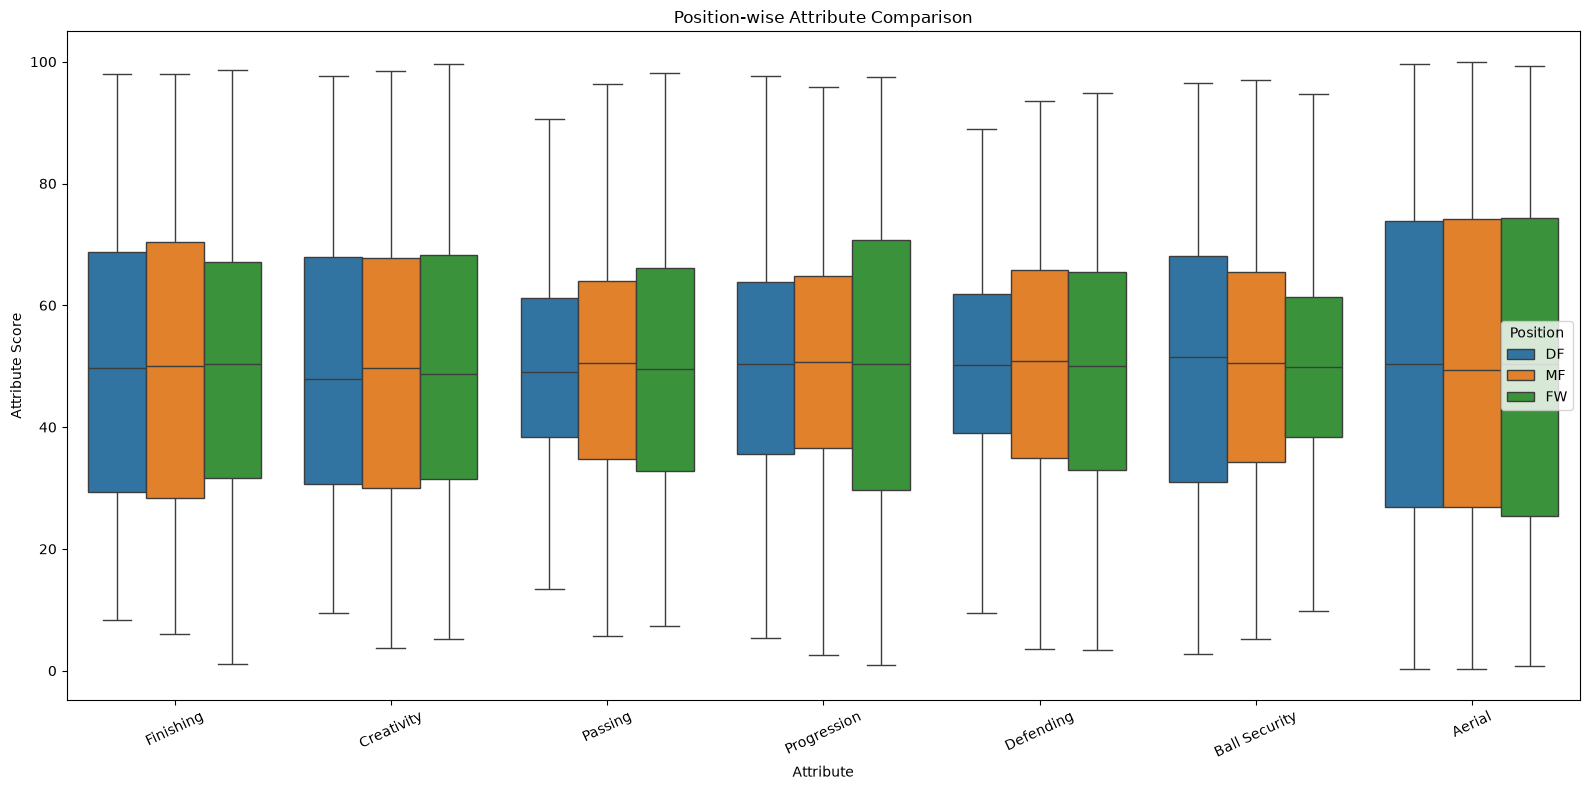

In [40]:
df_long = df.melt(
    id_vars=["Player", "Pos"],
    value_vars=ATTRIBUTE_COLUMNS,
    var_name="Attribute",
    value_name="Score"
)

df_long["Attribute"] = df_long["Attribute"].str.replace(
    "_Score", "", regex=False
)

df_long["Attribute"] = df_long["Attribute"].str.replace(
    "BallSecurity", "Ball Security"
)

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=df_long,
    x="Attribute",
    y="Score",
    hue="Pos",
    order=[
        "Finishing",
        "Creativity",
        "Passing",
        "Progression",
        "Defending",
        "Ball Security",
        "Aerial"
    ]
)

plt.title("Position-wise Attribute Comparison")
plt.xlabel("Attribute")
plt.ylabel("Attribute Score")
plt.xticks(rotation=25)
plt.legend(title="Position")
plt.tight_layout()
plt.show()

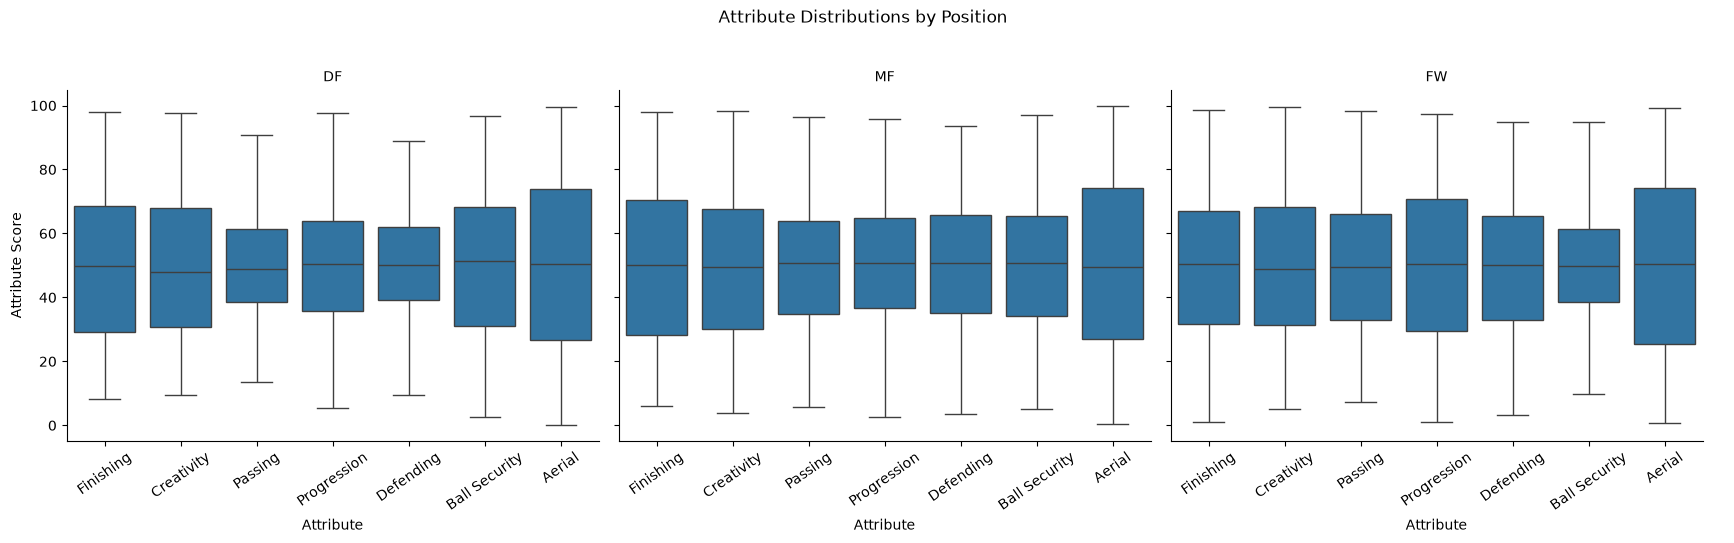

In [41]:
g = sns.catplot(
    data=df_long,
    x="Attribute",
    y="Score",
    col="Pos",
    kind="box",
    col_order=["DF", "MF", "FW"],
    height=5,
    aspect=1.15,
    sharey=True
)

g.set_axis_labels("Attribute", "Attribute Score")
g.set_titles("{col_name}")

g.set_xticklabels(rotation=35)
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Attribute Distributions by Position")

plt.show()

In [42]:
def plot_player_percentiles(player_name):

    player = df[df["Player"] == player_name]

    if player.empty:
        raise ValueError("Player not found.")

    if len(player) > 1:
        raise ValueError("Player name is not unique.")

    player = player.iloc[0]

    values = player[ATTRIBUTE_COLUMNS].values

    fig = go.Figure()

    fig.add_trace(go.Bar(
        x=values,
        y=ATTRIBUTE_LABELS,
        orientation="h",
        text=[f"{v:.1f}" for v in values],
        textposition="auto"
    ))

    fig.update_layout(
        title=f"{player_name} - Position-relative Attribute Percentiles",
        xaxis=dict(
            title="Percentile Score",
            range=[0, 100]
        ),
        yaxis=dict(title="Attribute"),
        template="plotly_white"
    )

    fig.show()

In [43]:
plot_player_percentiles("Erling Haaland")

In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# Prepare standardized attribute profiles
df_similarity_scaled = df.copy()

for position in sorted(df["Pos"].unique()):

    mask = df["Pos"] == position

    scaler = StandardScaler()

    df_similarity_scaled.loc[mask, ATTRIBUTE_COLUMNS] = (
        scaler.fit_transform(df.loc[mask, ATTRIBUTE_COLUMNS])
    )


def plot_similar_players(player_name, top_n=5):

    player_matches = df[df["Player"] == player_name]

    if len(player_matches) != 1:
        raise ValueError("Player name must uniquely identify one player.")

    player = player_matches.iloc[0]
    position = player["Pos"]

    candidates = df_similarity_scaled[
        df_similarity_scaled["Pos"] == position
    ].copy()

    player_index = player.name

    player_vector = df_similarity_scaled.loc[
        player_index, ATTRIBUTE_COLUMNS
    ].to_numpy().reshape(1, -1)

    candidate_vectors = candidates[ATTRIBUTE_COLUMNS].to_numpy()

    similarities = cosine_similarity(
        player_vector, candidate_vectors
    )[0]

    candidates["Similarity"] = similarities
    candidates = candidates[candidates.index != player_index]

    results = candidates.nlargest(top_n, "Similarity")

    fig = px.bar(
        results.sort_values("Similarity"),
        x="Similarity",
        y="Player",
        orientation="h",
        title=f"Players Similar to {player_name}",
        labels={
            "Similarity": "Cosine Similarity",
            "Player": "Player"
        },
        hover_data=["Squad", "Pos"],
        text="Similarity"
    )

    fig.update_traces(
        texttemplate="%{x:.2%}",
        textposition="outside"
    )

    fig.update_layout(
        template="plotly_white",
        xaxis_range=[0, 1.1]
    )

    fig.show()

In [45]:
plot_similar_players("Erling Haaland", top_n=5)

In [46]:
def plot_player_clusters(position):

    plot_data = df_clustered[
        df_clustered["Pos"] == position
    ].copy()

    fig = px.scatter(
        plot_data,
        x="PC1",
        y="PC2",
        color="PlayingStyle_Cluster",
        hover_name="Player",
        hover_data=[
            "Squad",
            "Finishing_Score",
            "Creativity_Score",
            "Passing_Score",
            "Progression_Score",
            "Defending_Score",
            "BallSecurity_Score",
            "Aerial_Score"
        ],
        title=f"{position} - Playing Style Clusters",
        labels={
            "PC1": "Principal Component 1",
            "PC2": "Principal Component 2",
            "PlayingStyle_Cluster": "Playing Style Cluster"
        }
    )

    fig.update_traces(
        marker=dict(size=8, opacity=0.75)
    )

    fig.update_layout(
        template="plotly_white",
        legend_title="Playing Style Cluster"
    )

    fig.show()

In [47]:
plot_player_clusters("FW")
plot_player_clusters("DF")
plot_player_clusters("MF")

In [48]:
def plot_top_players(attribute, position, top_n=10):

    if attribute not in ATTRIBUTE_COLUMNS:
        raise ValueError("Invalid attribute.")

    position_data = df[df["Pos"] == position].copy()

    top_players = position_data.nlargest(
        top_n,
        attribute
    ).sort_values(attribute)

    fig = px.bar(
        top_players,
        x=attribute,
        y="Player",
        orientation="h",
        hover_data=["Squad", "Nation"],
        title=f"Top {top_n} {position} Players - {attribute.replace('_Score', '')}"
    )

    fig.update_traces(
        texttemplate="%{x:.2f}",
        textposition="outside"
    )

    fig.update_layout(
        template="plotly_white",
        xaxis_title="Percentile Score",
        yaxis_title="Player",
        xaxis_range=[0, 105]
    )

    fig.show()

In [49]:
plot_top_players(
    "Finishing_Score",
    "FW",
    top_n=10
)

In [52]:
def plot_cluster_heatmap(position):

    # Filter the requested position
    position_summary = cluster_summary[
        cluster_summary["Pos"] == position
    ].copy()

    if position_summary.empty:
        raise ValueError(
            f"No cluster data found for position: {position}"
        )

    # Remove non-attribute columns
    position_summary = position_summary.drop(
        columns=["Pos", "Player_Count"],
        errors="ignore"
    )

    # Set cluster labels as index
    if "PlayingStyle_Cluster" in position_summary.columns:
        position_summary = position_summary.set_index(
            "PlayingStyle_Cluster"
        )

    plt.figure(figsize=(12, 5))

    sns.heatmap(
        position_summary,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn",
        vmin=0,
        vmax=100,
        linewidths=0.5
    )

    plt.title(
        f"{position} - Playing Style Cluster Profiles"
    )

    plt.xlabel("Attributes")
    plt.ylabel("Playing Style Cluster")

    plt.tight_layout()
    plt.show()

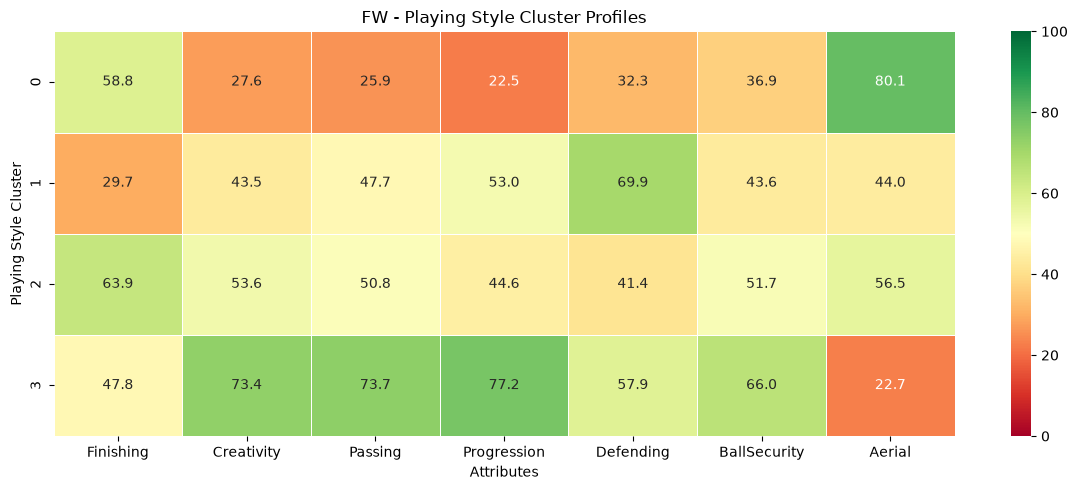

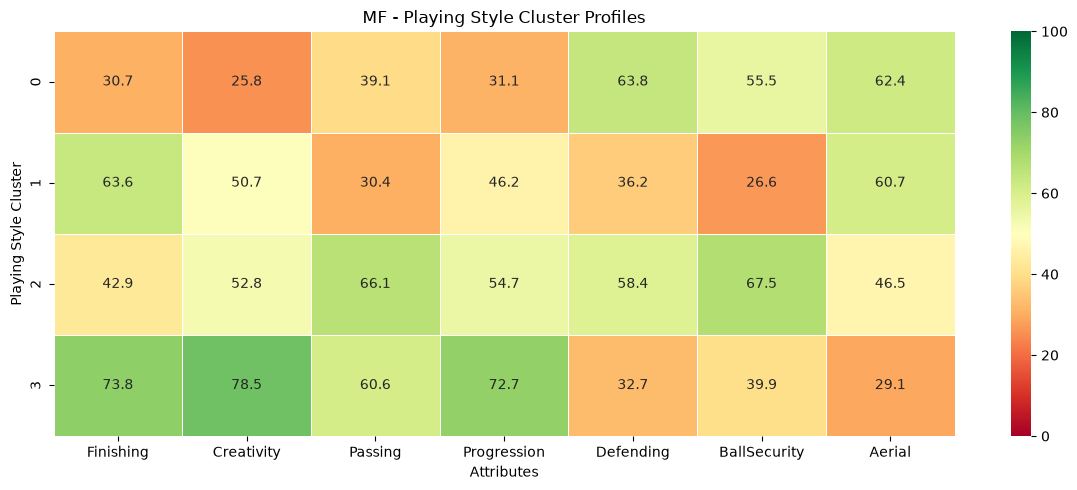

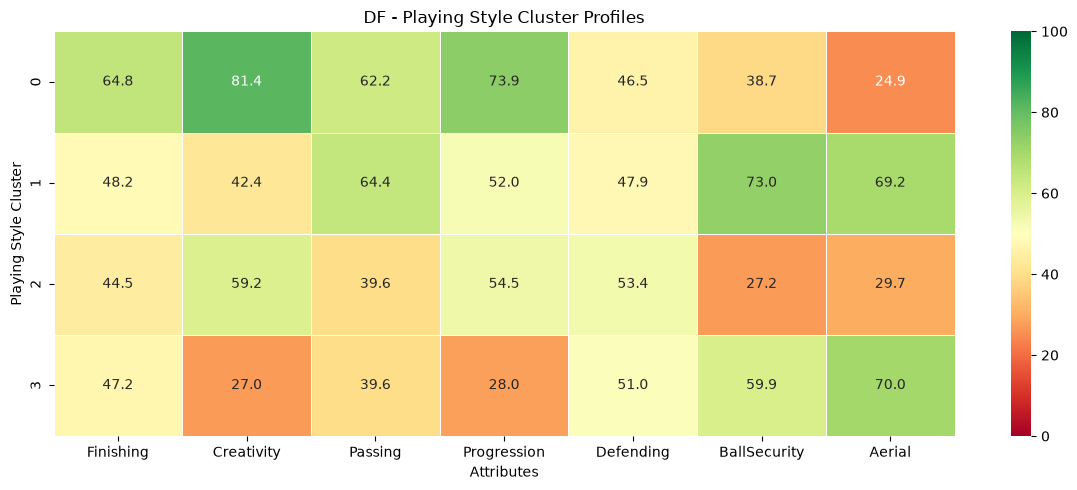

In [54]:
plot_cluster_heatmap("FW")
plot_cluster_heatmap("MF")
plot_cluster_heatmap("DF")